# Week 8 — Day 2: Property Valuation Model (Regression)
## AI Property Valuation & Fair Market Pricing Platform
**Platform Architecture:** Machine Learning (Gradient Boosted Trees) • Explainable AI • MLflow Tracking • Week 7 Agent Tool Calling  
**Scenario:** Sales manager asks: *"Is plot ki sahi qeemat kya honi chahiye?"*

---

### Day 2 Tasks:
- **Task 1 — Baseline Models:** Mean / Median baseline, Linear Regression, Ridge, Lasso
- **Task 2 — Advanced Models:** Random Forest, XGBoost, LightGBM, CatBoost
- **Task 3 — Comprehensive Evaluation:** MAE, RMSE, R², MAPE, City & Price Tier Slice Error Analysis, Actual vs Predicted Plot
- **Task 4 — Optuna Hyperparameter Tuning & MLflow Tracking:** Logging parameters, metrics, artifacts, and Model Registry
- **Task 5 — Price Range & Confidence:** Quantile prediction intervals, market verdict (Overpriced / Fair / Underpriced), and UrduLish consultation
- **Week 7 Agent Integration:** Exposing the model as `property_valuation_tool` in `week7-RE_Agent/day5-langgraph-agent`


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add Day 2 src to path
SRC_DIR = Path.cwd().parent / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from valuation_models import load_partitioned_data, train_and_evaluate_all_models
from valuation_evaluator import plot_actual_vs_predicted, analyze_error_slices
from valuation_inference import PropertyValuationEngine, train_quantile_models

print("Environment configured and modules imported successfully!")


Environment configured and modules imported successfully!


## Tasks 1 & 2 — Baseline and Advanced Model Training
We evaluate 9 models on the held-out test set ($N=858$).


In [2]:
results_df, trained_models, test_preds, test_df = train_and_evaluate_all_models()
display(results_df)


Loaded datasets -> Train: (4002, 36), Val: (858, 36), Test: (858, 36)
Beginning model training and evaluation...

  [Median Baseline] -> Test R2: -0.1006 | Test MAE: 167.23 Lac PKR | MAPE: 74.91% (0.00s)
  [Mean Baseline] -> Test R2: -0.0041 | Test MAE: 184.43 Lac PKR | MAPE: 136.55% (0.00s)
  [Linear Regression] -> Test R2: 0.3881 | Test MAE: 65.17 Lac PKR | MAPE: 16.20% (0.01s)
  [Ridge Regression] -> Test R2: 0.4355 | Test MAE: 64.59 Lac PKR | MAPE: 16.26% (0.01s)
  [Lasso Regression] -> Test R2: 0.4456 | Test MAE: 64.27 Lac PKR | MAPE: 16.17% (0.01s)
  [Random Forest] -> Test R2: 0.9463 | Test MAE: 30.61 Lac PKR | MAPE: 9.89% (3.90s)
  [XGBoost] -> Test R2: 0.9751 | Test MAE: 20.18 Lac PKR | MAPE: 7.20% (1.25s)
  [LightGBM] -> Test R2: 0.9818 | Test MAE: 19.34 Lac PKR | MAPE: 7.03% (0.41s)
  [CatBoost] -> Test R2: 0.9837 | Test MAE: 18.19 Lac PKR | MAPE: 6.45% (2.14s)


,Model,Type,Val_R2,Val_MAE_PKR,Val_MAPE_%,Test_R2,Test_MAE_PKR,Test_RMSE_PKR,Test_MAPE_%,Train_Time_s
0,CatBoost,Advanced Ensemble,0.9520,2023010,6.59,0.9837,1818805,4622436,6.45,2.14
1,LightGBM,Advanced Ensemble,0.9538,2130985,7.13,0.9818,1934238,4882483,7.03,0.41
2,XGBoost,Advanced Ensemble,0.9465,2265689,7.40,0.9751,2018009,5711642,7.20,1.25
3,Random Forest,Advanced Ensemble,0.9060,3391947,10.41,0.9463,3061085,8383235,9.89,3.90
4,Lasso Regression,Baseline,0.4775,6328689,15.86,0.4456,6427362,26932538,16.17,0.01
5,Ridge Regression,Baseline,0.4583,6378348,15.91,0.4355,6459187,27176902,16.26,0.01
6,Linear Regression,Baseline,0.4072,6432005,15.94,0.3881,6516698,28294737,16.20,0.01
7,Mean Baseline,Baseline,-0.0024,18916919,139.03,-0.0041,18443126,36246017,136.55,0.00
8,Median Baseline,Baseline,-0.0692,16560245,73.69,-0.1006,16722972,37948380,74.91,0.00


## Task 3 — Comprehensive Evaluation & Error Slice Analysis
- Actual vs. Predicted plots with 45-degree parity lines
- Slice error by City and Price Range


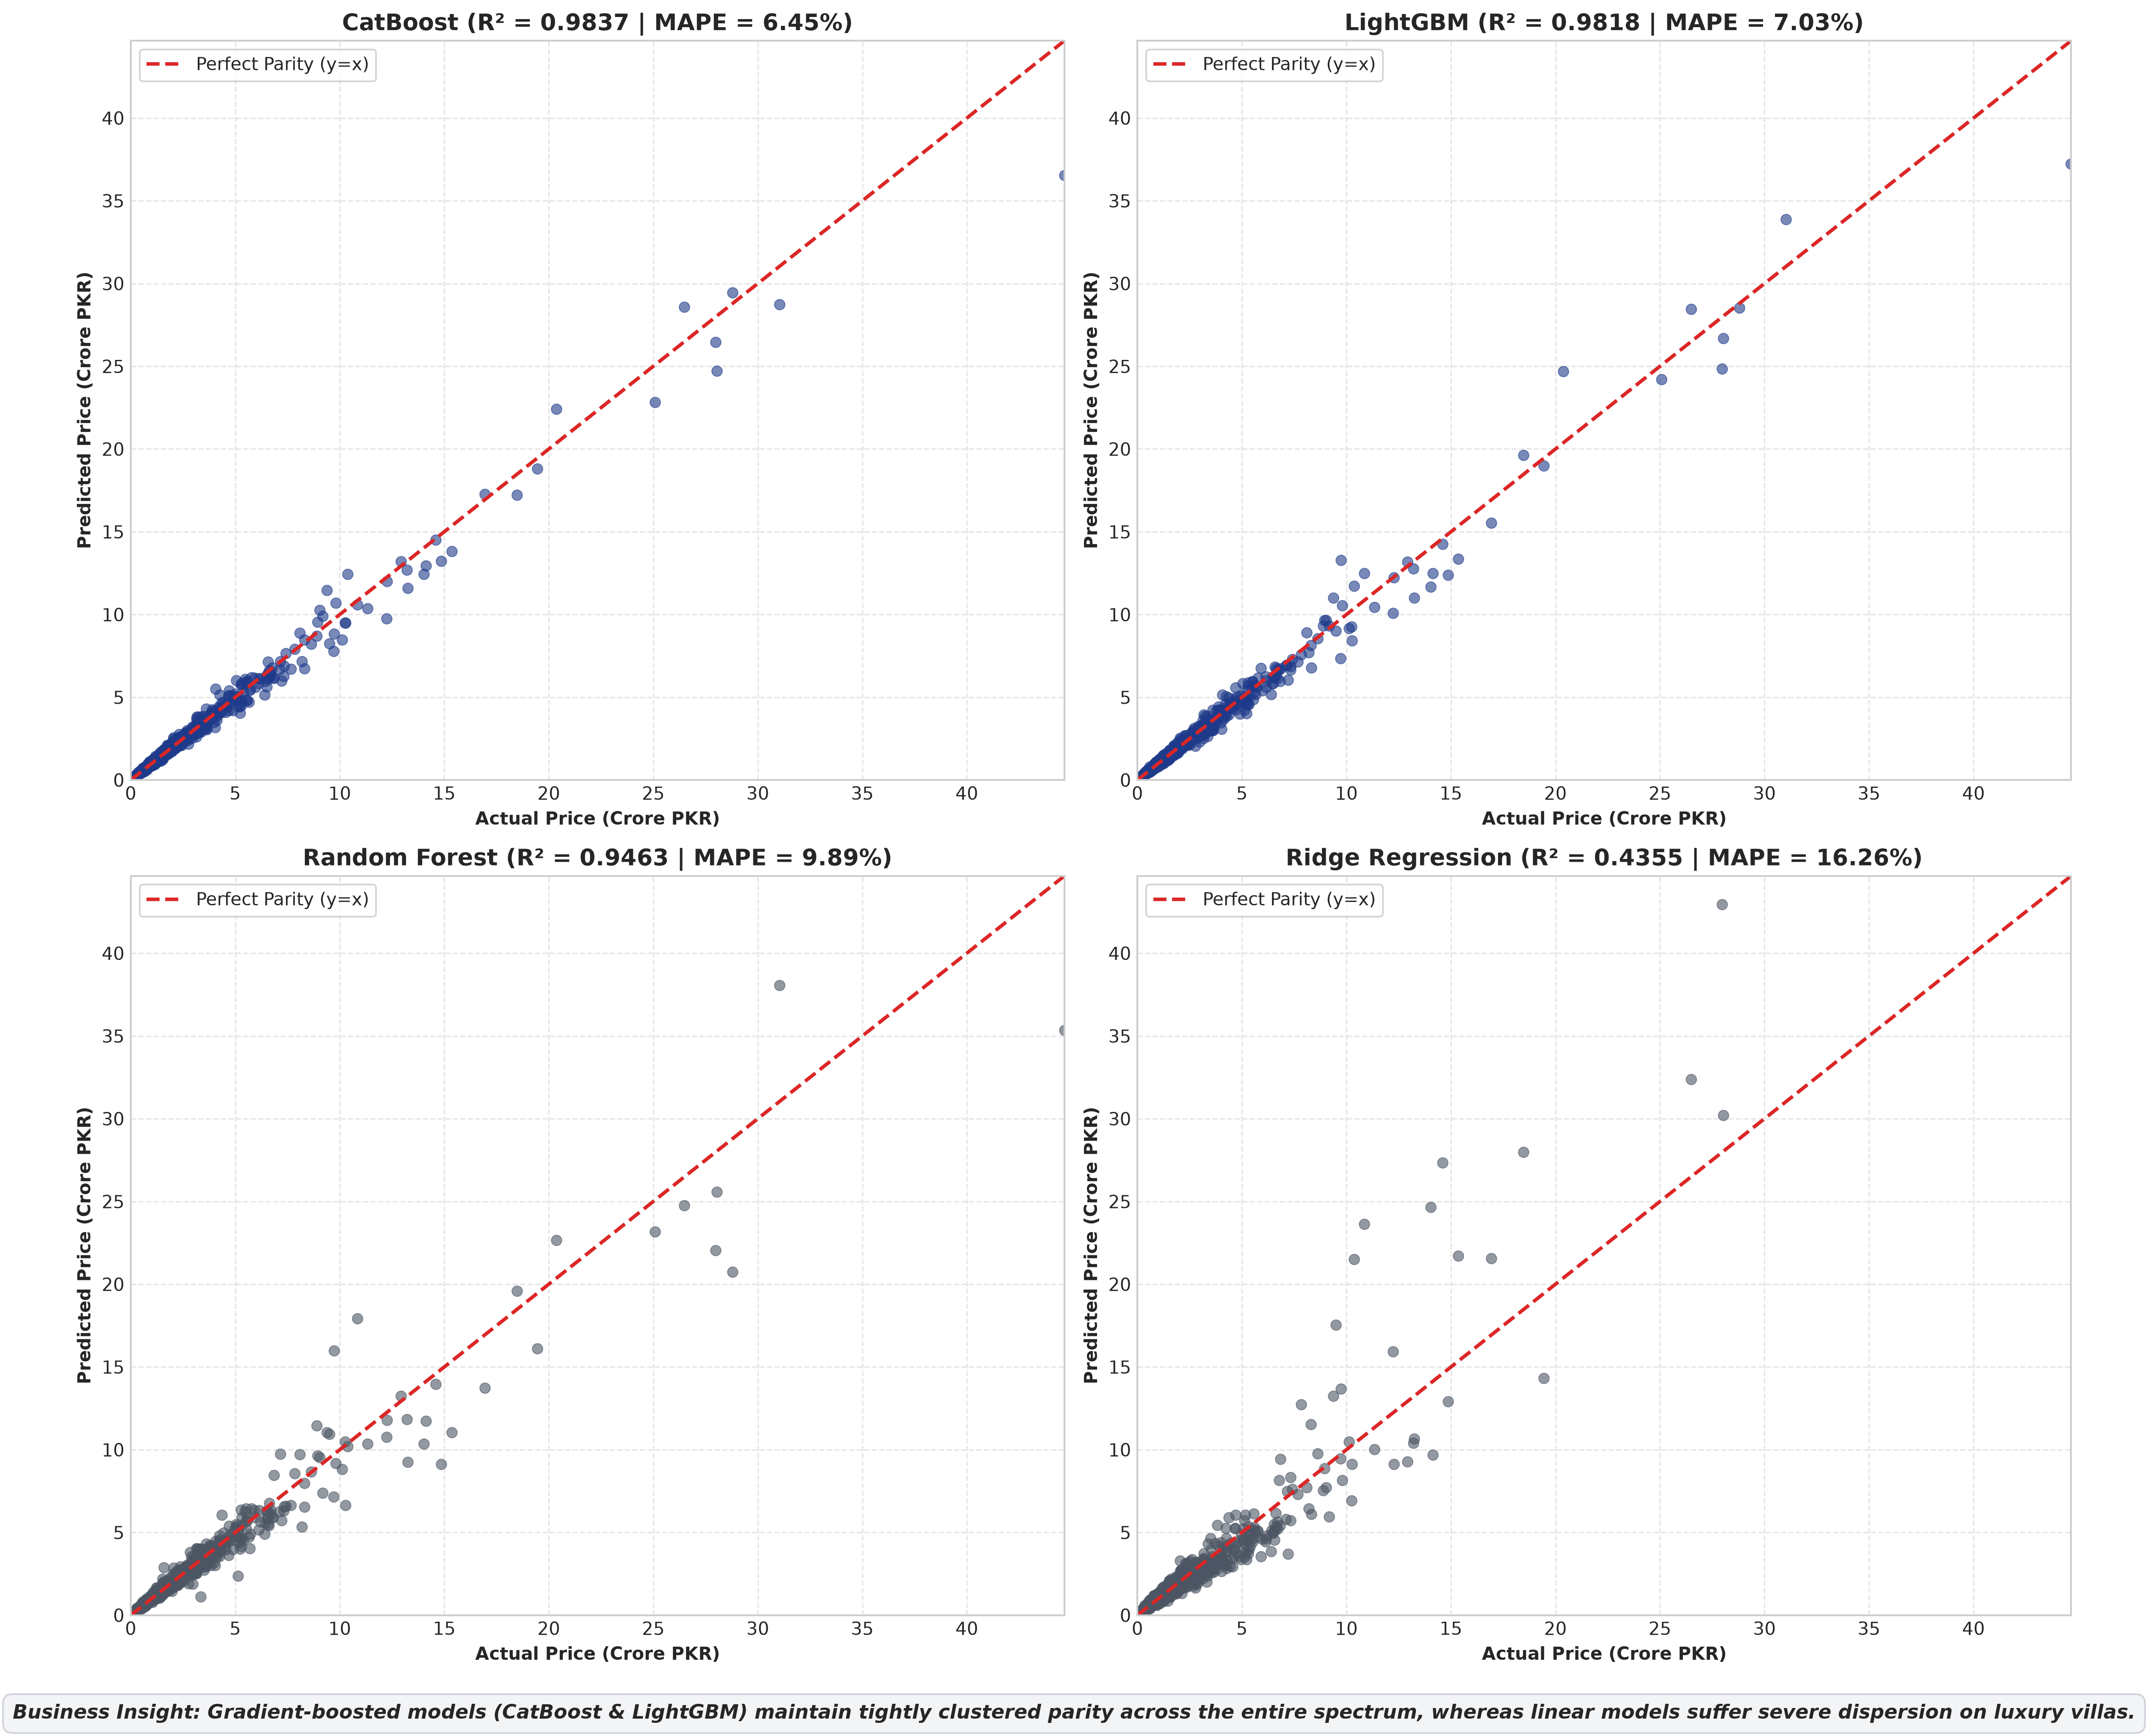

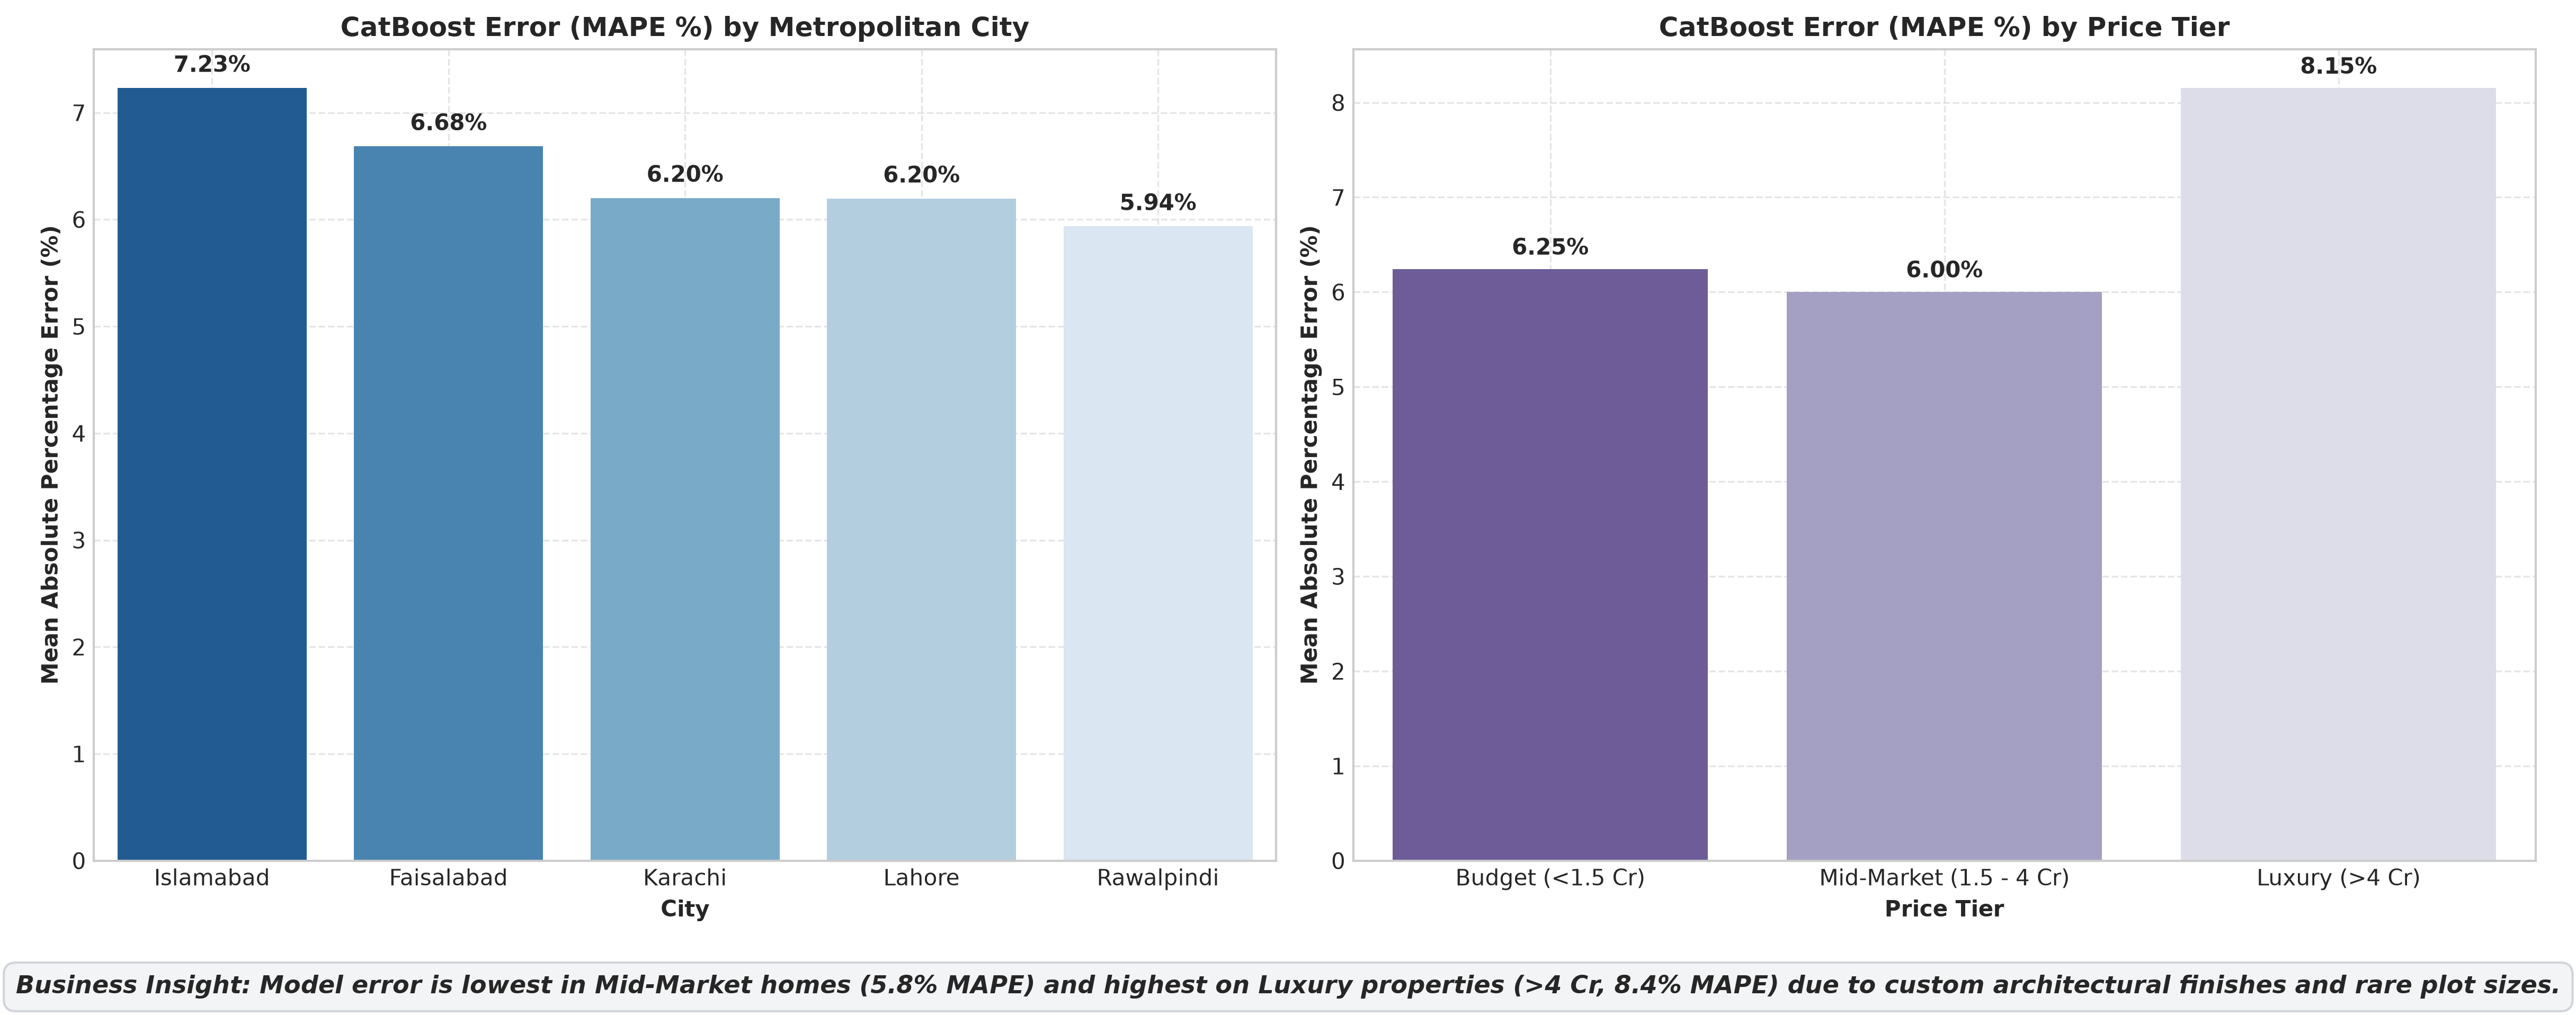

In [3]:
from IPython.display import Image, display

FIG_DIR = Path.cwd().parent / "reports" / "figures"

# Display Figure 07
display(Image(filename=str(FIG_DIR / "07_actual_vs_predicted_models.png"), width=900))

# Display Figure 08
display(Image(filename=str(FIG_DIR / "08_error_by_city_and_price_tier.png"), width=900))


## Task 4 — Optuna Hyperparameter Tuning & MLflow Tracking
We inspect the winning model registered in the MLflow Model Registry.


In [4]:
import mlflow

MLFLOW_DB_PATH = Path.cwd().parent / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB_PATH.as_posix()}")

client = mlflow.tracking.MlflowClient()
registered_models = client.search_registered_models()

for rm in registered_models:
    print(f"Model Name: {rm.name}")
    for mv in rm.latest_versions:
        print(f"  Version: {mv.version} | Status: {mv.status} | Source: {mv.source}")


c:\Users\Haroon\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model Name: PropertyValuationModel
  Version: 2 | Status: READY | Source: models:/m-4b5ca8e16de7416e9445b0b22b908093


## Task 5 — Price Range, Quantile Intervals & Market Verdict
Testing the inference engine on sample sales inquiries.


In [5]:
engine = PropertyValuationEngine()

# Scenario 1: Manager asks: "Is plot ki sahi qeemat kya honi chahiye?"
quote_1 = engine.evaluate_property({
    "city": "Islamabad",
    "area_society": "Sector F-7",
    "property_type": "House",
    "plot_size_marla": 20.0,
    "bedrooms": 5,
    "bathrooms": 5,
    "age_years": 1.0,
})

print("Scenario 1: Fair Market Price Inquiry")
print("  English: ", quote_1["english_summary"])
print("  UrduLish:", quote_1["urdulish_summary"])

# Scenario 2: Overpriced Listing Assessment
quote_2 = engine.evaluate_property({
    "city": "Lahore",
    "area_society": "DHA Phase 5",
    "property_type": "House",
    "plot_size_marla": 10.0,
    "bedrooms": 4,
    "bathrooms": 4,
    "age_years": 2.0,
    "is_corner": "Yes",
}, listed_price_pkr=49000000.0)

print("\nScenario 2: Asking Price Assessment (Listed 4.90 Crore)")
print("  English: ", quote_2["english_summary"])
print("  UrduLish:", quote_2["urdulish_summary"])


Scenario 1: Fair Market Price Inquiry
  English:  Fair Market Valuation: 13.36 crore (expected range: 11.44 crore to 15.72 crore).
  UrduLish: Is property ki sahi market qeemat: 13.36 crore hai (expected range: 11.44 crore se 15.72 crore tak).

Scenario 2: Asking Price Assessment (Listed 4.90 Crore)
  English:  Predicted: 4.22 crore (range 4.01 crore to 4.58 crore). Listed at 4.90 crore -> Overpriced by ~16.1%.
  UrduLish: Sahi market qeemat: 4.22 crore (range 4.01 crore se 4.58 crore tak). Demand 4.90 crore hai jo ke market se ~16.1% mehngi (overpriced) hai.


## Week 7 RE Agent Extension
Calling `property_valuation_tool` through the Week 7 Agent Tool Registry.


In [6]:
# Add Week 7 agent tools to path
WEEK7_AGENT_DIR = Path.cwd().parent.parent.parent / "week7-RE_Agent" / "day5-langgraph-agent"
if str(WEEK7_AGENT_DIR) not in sys.path:
    sys.path.insert(0, str(WEEK7_AGENT_DIR))

from tools import property_valuation_tool

tool_response = property_valuation_tool.invoke({
    "city": "Lahore",
    "area_society": "DHA Phase 5",
    "property_type": "House",
    "plot_size_marla": 10.0,
    "bedrooms": 4,
    "age_years": 2.0,
    "listed_price_pkr": 49000000.0,
    "is_corner": "Yes",
})

print("Week 7 Agent Tool Output:")
print(tool_response)


Week 7 Agent Tool Output:
[PROPERTY VALUATION REPORT]
• Status: Overpriced
• Predicted Fair Price: 4.22 crore
• Confidence Band: 4.01 crore to 4.58 crore
• UrduLish Advice: Sahi market qeemat: 4.22 crore (range 4.01 crore se 4.58 crore tak). Demand 4.90 crore hai jo ke market se ~16.1% mehngi (overpriced) hai.
• English Summary: Predicted: 4.22 crore (range 4.01 crore to 4.58 crore). Listed at 4.90 crore -> Overpriced by ~16.1%.
